In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
logs = [
    # '/data/models/bin/2026_pathway_generation/reference_logs/resnet18_ddp_graph_20260209_121921/',
    '/data/models/bin/2026_pathway_generation/reference_logs/swin_tiny_ddp_graph_20260211_220834_0.2/',
    '/data/models/bin/2026_pathway_generation/reference_logs/swin_tiny_ddp_graph_20260211_152110_0.4/',
    '/data/models/bin/2026_pathway_generation/reference_logs/swin_tiny_ddp_graph_20260212_103706_0.6/',
    '/data/models/bin/2026_pathway_generation/reference_logs/swin_tiny_ddp_graph_20260212_221908_0.8/',
    '/data/models/bin/2026_pathway_generation/reference_logs/swin_tiny_ddp_graph_20260212_123147/'
]
labels = [#'resbet18', 
          'swin (20%)', 'swin (40%)', 'swin (60%)', 'swin (80%)', 'swin (100%)']

In [3]:
log = '/data/models/bin/2026_pathway_generation/reference_logs/swin_tiny_ddp_graph_20260206_130501/'
loss = np.load(log+'loss_log.pkl', allow_pickle=True)
train_full = np.stack(loss['train'])[:,2]
val_full = np.stack(loss['val'])[:,2]

swin (20%) -- Train Min: (1.1054). Val Min: (1.2381)
swin (40%) -- Train Min: (1.1369). Val Min: (1.1541)
swin (60%) -- Train Min: (1.09). Val Min: (1.0735)
swin (80%) -- Train Min: (1.002). Val Min: (1.0234)
swin (100%) -- Train Min: (0.7869). Val Min: (0.9589)


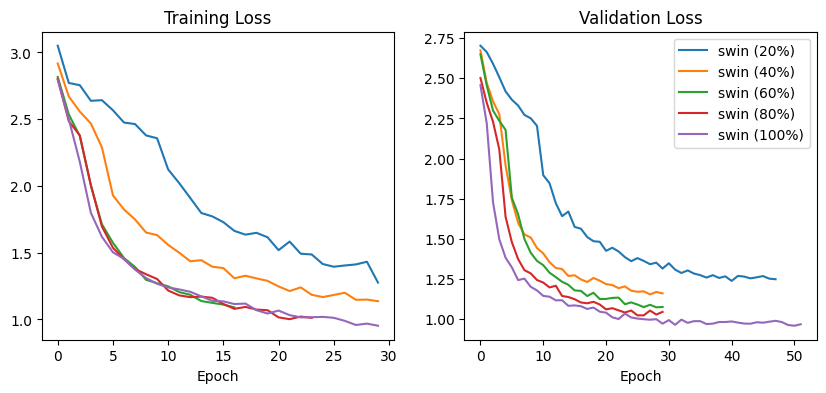

In [4]:
fig, axs = plt.subplots(1,2, figsize=(10,4))
for i, log in enumerate(logs):
    loss = np.load(log+'loss_log.pkl', allow_pickle=True)
    train = np.stack(loss['train'])
    val = np.stack(loss['val'])    
    if '2026_pathway_generation' in log:
        train = train[:,2]
        val = val[:,2]
        if 'swin_tiny_ddp_graph_20260212_123147' in log:
            train = np.concatenate([train_full, train])
            val = np.concat([val_full, val])
        
        if 'ddp' in log:
            if '0.2' in log: n = 115
            elif '0.4' in log: n = 229
            else: n = 572
            count = len(train)//n
            train = [np.mean(train[i*n:(i+1)*n]) for i in range(count)]
        else:
            count = len(train)//2288
            train = [np.mean(train[i*2288:(i+1)*2288]) for i in range(count)]
    print(f'{labels[i]} -- Train Min: ({round(np.min(train), 4)}). Val Min: ({round(np.min(val), 4)})')
    axs[0].plot(train[:30], label=labels[i])
    axs[0].set_title('Training Loss')
    axs[0].set_xlabel('Epoch')
    axs[1].plot(val, label=labels[i])
    axs[1].set_title('Validation Loss')
    axs[1].set_xlabel('Epoch')
    plt.legend()
pass